# Customer Segmentation for Mall Customers - (UnSupervised Learning - Clustering)

## Objective:
Group mall customers into distinct segments based on their spending behavior and demographics using unsupervised clustering algorithms.

## Learning Goals:
* Unsupervised Learning: No target variable to predict!

* Clustering Fundamentals: Discover natural groupings in data

* Feature Scaling: Critical for distance-based algorithms

* Choosing K: How many clusters make sense?

* Interpretation: What do these clusters represent in business terms?

In [70]:
# Importation Libraries :

import pandas as pd 
import numpy as np

import matplotlib.pyplot as plt 
import seaborn as sns

In [71]:
df = pd.read_csv('Mall_Customers.csv')
df.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


# EDA (Exploration data analysis)

## Columns Explination :
* CustomerID: Unique ID for each customer
* Gender: Male/Female
* Age: Customer's age
* Annual Income (k$): Annual income in thousands of dollars
* Spending Score (1-100): Mall's rating of customer spending behavior

## Analyse de Forme :
* identify target => we dont have target (since we have unsupervised learning:we gonna orginase n discover hidden pattern of customers by spending) 
* num of ligne & colonne => lignnes/exemples=200, colonnes/features=5 
* type des variables(features) => 4 int('CustomerID', 'Age', 'Annual Income (k$)','Spending Score (1-100)') and 1 object/string('Gender')
* identifiant Nan (missing values) => No Nan :)

## Analyse de Forme :
* Visualisation de target => (not used in this case)

* Comprehension des diff var (seperatly) =>
#as was expected Female more than Male #female are more than male Female:112/ Male:88
#Spending Score btw(35-75)
#Income(Annual Income) in averge btw (40-80)
#Age go btw (20's-30's-40's-50's) btw(20-50)

* Visualisation des relations entre features with each others =>
#male make more income than Female
#Female spent more than male
#(male attend to live a little longer than female)
#we can say that people in 30's to 40's have higher incomes
#we observe that people btw 20-40 spending score is(40 to 100) n people btw 40-70 spending score is(0-58)
#means that young people(20-40) spend more than older people(40-70)
#not huge correlation btw features

* Visualisation des relations entre features with target(not used) =>

* Identification des outliers =>
#we dont have outliers(just 2 in column Annual Income (k$))
#we remove 2 lignes that had it so our data set (198,5)

* Elimine some columns that arent important like:
#remove the colonne of IdCustomer not important 

In [72]:
df.shape

(200, 5)

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [74]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

C:\Users\hp\AppData\Local\Temp\ipykernel_13228\3876482814.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Gender', data=df , palette='Set2')


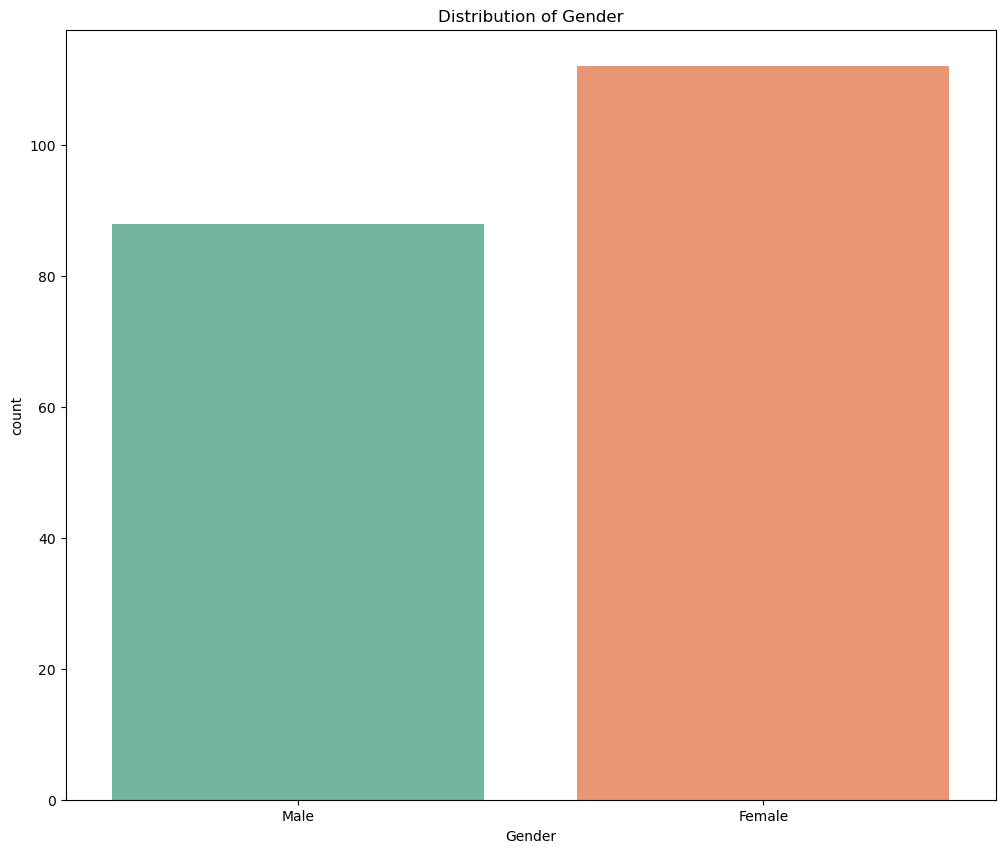

In [75]:
plt.figure(figsize=(12,10))
sns.countplot(x='Gender', data=df , palette='Set2')
plt.title('Distribution of Gender')
plt.show() # as was expected Female attend to buy/spend more than Male

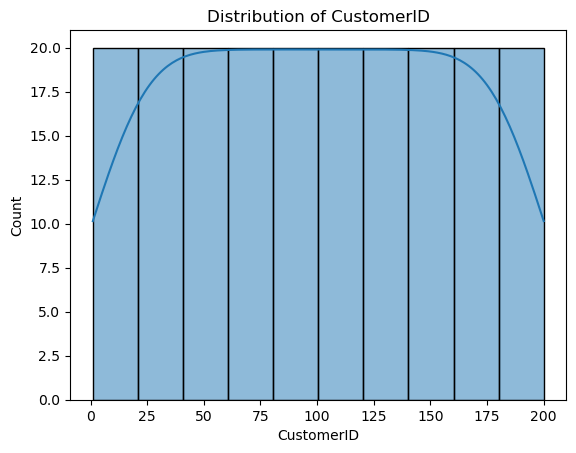

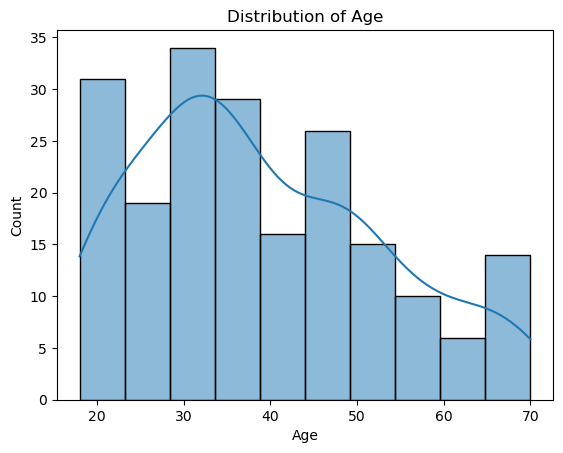

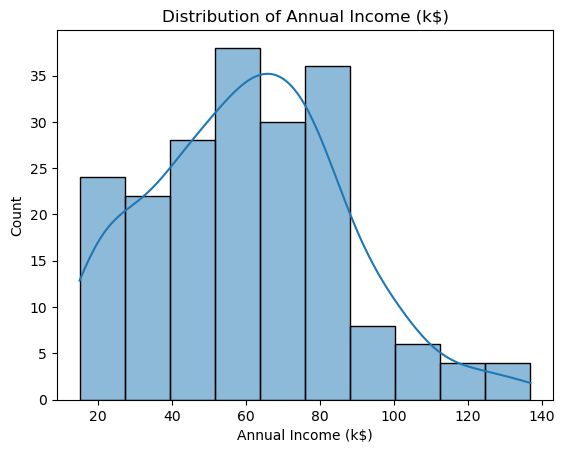

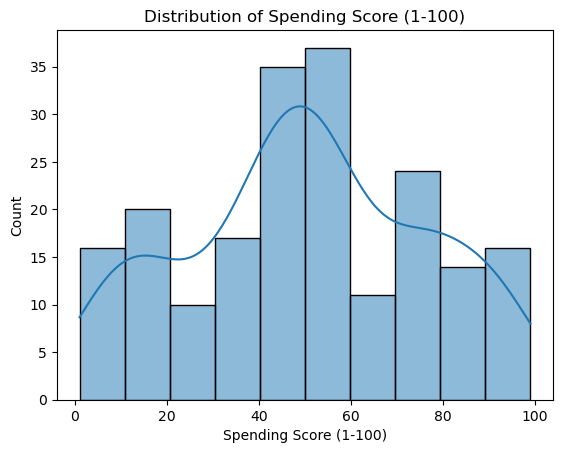

In [76]:
num_cols= df.select_dtypes(include=['int']).columns
for col in num_cols:
    sns.histplot(df[col],kde=True,bins=10)
    plt.title(f'Distribution of {col}')
    plt.show()

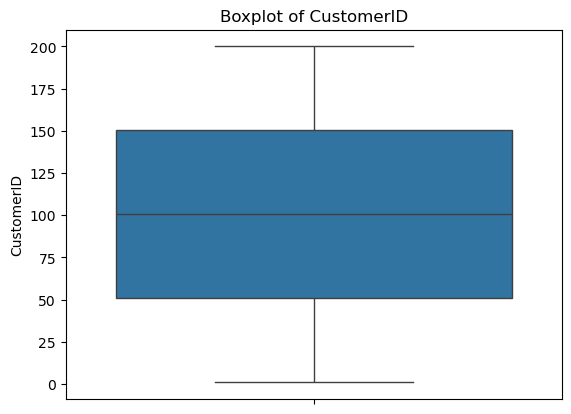

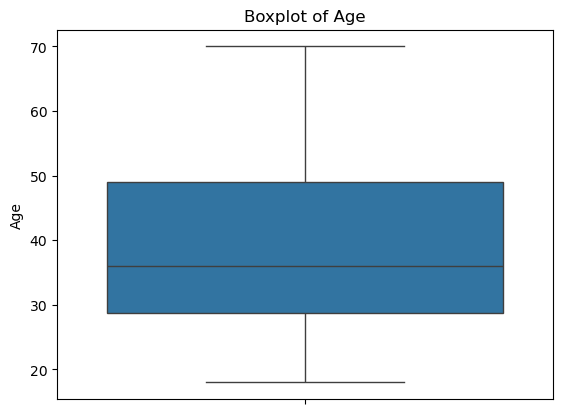

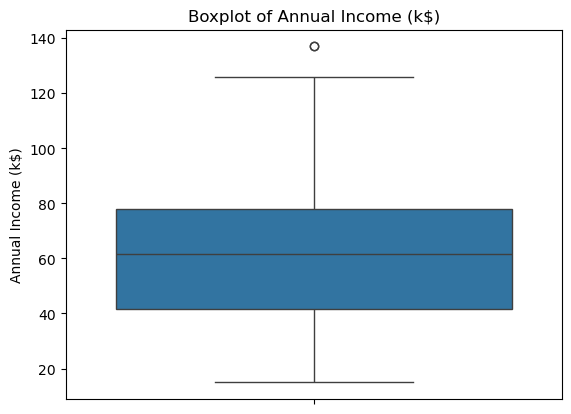

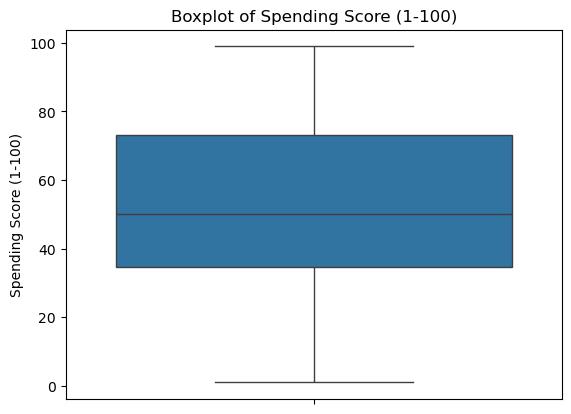

In [77]:
for col in num_cols:
    sns.boxplot(df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

<Figure size 1200x1000 with 0 Axes>

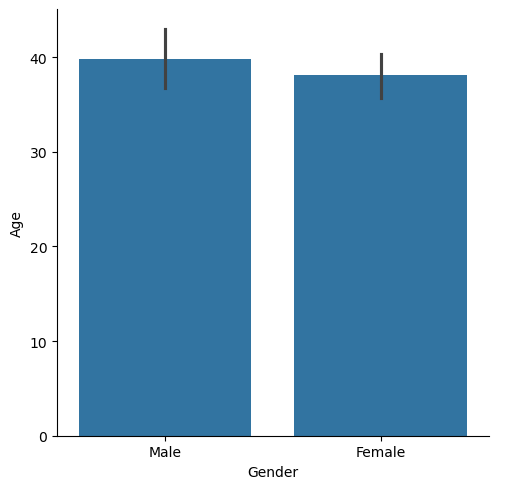

In [78]:
# relation btw features 
plt.figure(figsize=(12,10))
sns.catplot(x='Gender' , y='Age' , data=df , kind='bar')
plt.show() #(male attend to live a little longer than female)

<Figure size 1200x1000 with 0 Axes>

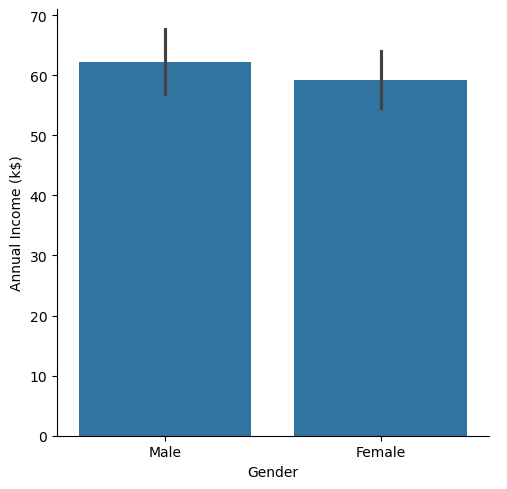

In [79]:
plt.figure(figsize=(12,10))
sns.catplot(x='Gender' , y='Annual Income (k$)' , data=df , kind='bar')
plt.show() #male make more income than Female

<Axes: xlabel='Gender', ylabel='Spending Score (1-100)'>

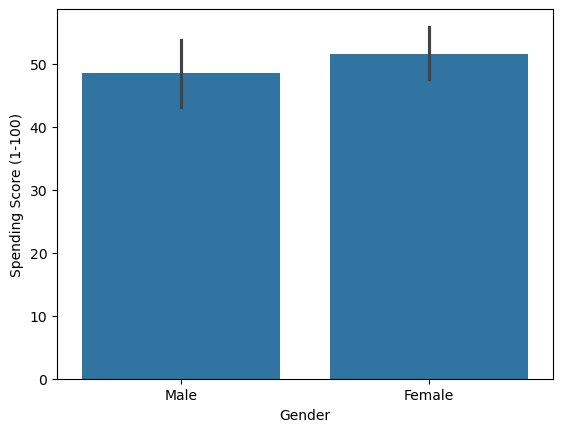

In [80]:
sns.barplot(x='Gender' , y='Spending Score (1-100)', data=df)
#Female spent more than male

In [81]:
df['Gender'].value_counts() #female are more than male Female:112/ Male:88

Gender
Female    112
Male       88
Name: count, dtype: int64

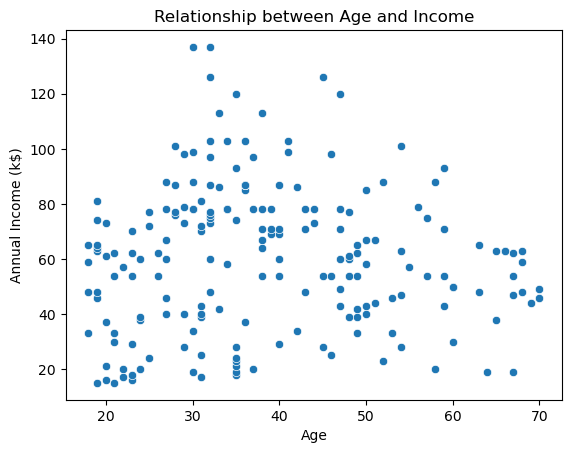

In [82]:
sns.scatterplot(x='Age', y='Annual Income (k$)', data=df) 
plt.title('Relationship between Age and Income') 
plt.show() # we can say that people in 30's to 40's have higher incomes 

Text(0.5, 1.0, 'Relationship between Age and Spending')

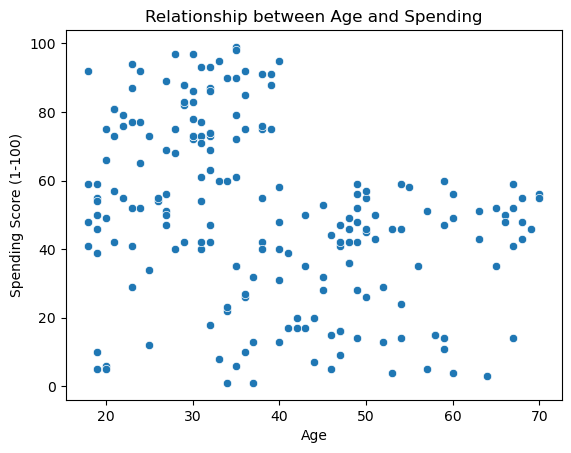

In [83]:
sns.scatterplot(x='Age', y='Spending Score (1-100)', data=df) 
plt.title('Relationship between Age and Spending') 
# we observe that people btw 20-40 spending score is(40 to 100) n people btw 40-70 spending score is(0-58)
#means that young people(20-40) spend more than older people(40-70)

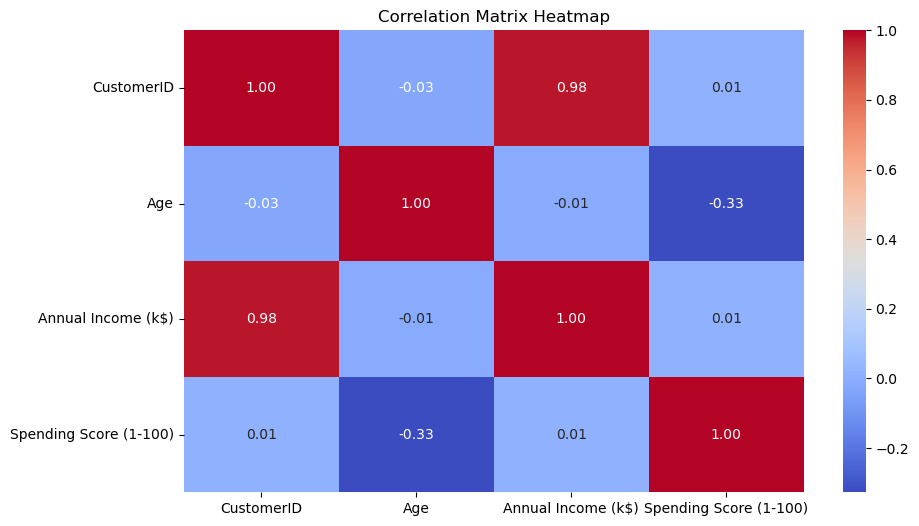

In [84]:

# Step 1: Select only numeric columns
numeric_df = df.select_dtypes(include=['number'])

# Step 2: Compute correlation matrix
corr_matrix = numeric_df.corr()

# Step 3: Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()
#not huge correlation btw features

In [85]:
# Separate numeric columns
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

# --- Initialize dictionary ---
outlier_counts = {}

# --- Detect outliers using IQR method ---
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))]
    outlier_counts[col] = len(outliers)

# --- Convert to Series and sort ---
outlier_counts = pd.Series(outlier_counts).sort_values(ascending=False)

print(outlier_counts) # we dont have outliers(just 2 in column Annual Income (k$))

Annual Income (k$)        2
CustomerID                0
Age                       0
Spending Score (1-100)    0
dtype: int64


In [86]:
def remove_outliers(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

# Example usage:
df_clean = remove_outliers(df, "Annual Income (k$)")


In [87]:
df_clean.shape # we removed the 2 lines that had outliers 

(198, 5)

In [88]:
df_1 = df_clean.drop(['CustomerID'],axis=1) # remove column CustomerID since its not important
df_1.head(10)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
5,Female,22,17,76
6,Female,35,18,6
7,Female,23,18,94
8,Male,64,19,3
9,Female,30,19,72


## Pre-processing
is the process of getting our dataset ready for model training. In this section, we will perform the following preprocessing steps:

* Data cleaning (lignes(duplicate/non pertinetes)- colonne(redandance/donnees incorrect/nan/outliers)
* Create Train Test set (not used for unsupervised learning)
* Drop and fill missing values (no used)
* Encoding 
* Data trasformation (log transformation) - suppression outliers (not used)
* Feature engineering
* Features Scaling 

In [89]:
df_1.duplicated() # no dulicated lignes(exemples)

0      False
1      False
2      False
3      False
4      False
       ...  
193    False
194    False
195    False
196    False
197    False
Length: 198, dtype: bool

In [90]:
df_1.isnull().sum() #no nan

Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [91]:
df_1.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,198.0,38.929293,14.016852,18.0,28.25,36.0,49.00,70.0
Annual Income (k$),198.0,59.787879,25.237259,15.0,40.50,61.0,77.75,126.0
Spending Score (1-100),198.0,50.196970,25.746846,1.0,35.00,50.0,72.75,99.0


In [92]:
# Encoding  column Gender(M:0 & F:1)

genders = {'Male':0 , 'Female':1}
df_1['Sex'] = df_1['Gender'].map(genders)

In [93]:
df_1.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Sex
0,Male,19,15,39,0
1,Male,21,15,81,0
2,Female,20,16,6,1
3,Female,23,16,77,1
4,Female,31,17,40,1


### Feature Enginneering 
process of creating, transforming, or selecting features (variables) from raw data to improve the performance of machine learning models.

In [94]:
import pandas as pd

# Create new feature1: Income per Age
df_1['Income_per_Age'] = df_1['Annual Income (k$)'] / df['Age']


In [95]:

# Define bins based on min/max
bins = [15, 40, 80, 126]   # ranges
labels = [0, 1, 2]         # 0=Low, 1=Medium, 2=High

df_1['IncomeBucket'] = pd.cut(df_1['Annual Income (k$)'], bins=bins, labels=labels, include_lowest=True)

print(df_1[['Annual Income (k$)', 'IncomeBucket']].head())


   Annual Income (k$) IncomeBucket
0                  15            0
1                  15            0
2                  16            0
3                  16            0
4                  17            0


In [96]:
df_1['IncomeBucket'].value_counts()

IncomeBucket
1    112
0     50
2     36
Name: count, dtype: int64

In [97]:
df_1.describe()

,Age,Annual Income (k$),Spending Score (1-100),Sex,Income_per_Age
count,198.000000,198.000000,198.000000,198.000000,198.000000
mean,38.929293,59.787879,50.196970,0.565657,1.724663
std,14.016852,25.237259,25.746846,0.496927,0.920492
min,18.000000,15.000000,1.000000,0.000000,0.283582
25%,28.250000,40.500000,35.000000,0.000000,0.910542
50%,36.000000,61.000000,50.000000,1.000000,1.573850
75%,49.000000,77.750000,72.750000,1.000000,2.419956
max,70.000000,126.000000,99.000000,1.000000,4.263158


In [104]:
df_1= df_1.drop(['IncomeBucket'],axis=1)

In [105]:
df_1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 198 entries, 0 to 197
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     198 non-null    int64  
 1   Annual Income (k$)      198 non-null    int64  
 2   Spending Score (1-100)  198 non-null    int64  
 3   Sex                     198 non-null    int64  
 4   Income_per_Age          198 non-null    float64
dtypes: float64(1), int64(4)
memory usage: 9.3 KB


## Feature Scaling

* Normalization (Min-Max) =>This rescales values into a fixed range, usually [0,1].
* Standardization (Z-score Scaling)=>This rescales values so that each feature has mean = 0 and standard deviation = 1.

how to choose :

*If your features have different ranges but are bounded, use Normalization.
* If your features have different distributions or unbounded values, use Standardization.
* If unsure, start with Standardization — it’s more robust in practice.

In [106]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled  =scaler.fit_transform(df_1)

# Modelling 

In [65]:
# model 1 : K-Means Clustering

In [134]:
from sklearn.cluster import KMeans

# Example: K-Means
kmeans = KMeans(n_clusters=9, random_state=42)
labels = kmeans.fit_predict(X_scaled)

df_1['Cluster'] = labels   # add cluster labels back to dataframe


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [135]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

print("Silhouette Score:", silhouette_score(X_scaled, labels))
print("Davies-Bouldin Index:", davies_bouldin_score(X_scaled, labels))
print("Calinski-Harabasz Index:", calinski_harabasz_score(X_scaled, labels))


Silhouette Score: 0.3343286138995896
Davies-Bouldin Index: 0.963738394781426
Calinski-Harabasz Index: 68.68401966270109


* Silhouette Score (Higher = better separation between clusters)  → Measures how well each point fits into its cluster compared to others; closer to 1 is better, so 0.33 means clusters are only moderately separated.

* Davies‑Bouldin Index (Lower = better) → Evaluates how similar clusters are to each other; lower is better, and 1.08 suggests clusters are somewhat distinct but not very tight.

* Calinski‑Harabasz Index (Higher = better ) → Compares between‑cluster separation to within‑cluster compactness; higher is better, so 71.8 is decent but should be compared across different numbers of clusters.

C:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

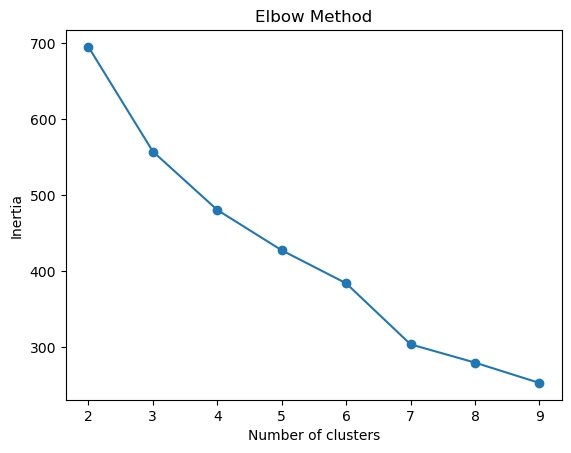

In [136]:
import matplotlib.pyplot as plt

inertia = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.plot(range(2, 10), inertia, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()


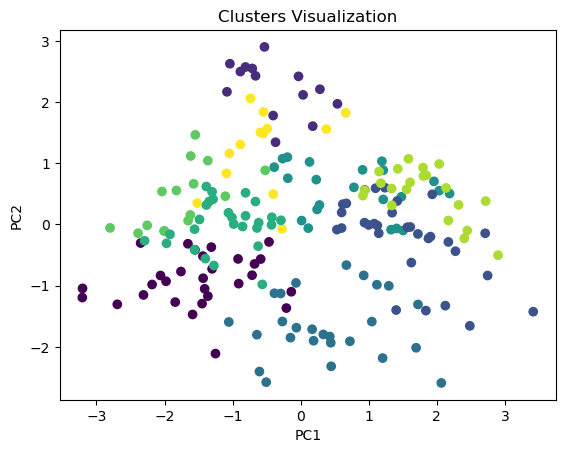

In [137]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap='viridis')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters Visualization')
plt.show()


In [138]:
# model 2 :Gaussian Mixture Models (GMM)

#### Why use it?

* Unlike K-Means (which assumes spherical clusters), GMM allows clusters to have different shapes and sizes.

* It’s probabilistic: each point has a probability of belonging to a cluster.

* Often gives better Silhouette/Davies-Bouldin scores when clusters aren’t perfectly round

In [145]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=2, random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)

# Evaluate
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
print("Silhouette:", silhouette_score(X_scaled, labels_gmm))
print("DBI:", davies_bouldin_score(X_scaled, labels_gmm))
print("CHI:", calinski_harabasz_score(X_scaled, labels_gmm))


Silhouette: 0.2508846528752142
DBI: 1.5398234931665145
CHI: 75.20081984925838


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


### Here’s how to interpret them in simple terms:

* Silhouette Score (0.27)
Range: -1 → 1 / Higher = better separation between clusters.

Rule of thumb:
* 0.5 = good
* 0.25–0.5 = weak/moderate
* <0.25 = poor separation

* Davies-Bouldin Index (1.26)
Range: 0 → ∞ / Lower = better (clusters are compact and far apart).

Rule of thumb:
* <1 = good
* 1–2 = moderate
* 2 = poor


* Calinski-Harabasz Index 
Higher = better (compares between-cluster separation vs. within-cluster compactness).
Rule of thumb: only meaningful when comparing across different numbers of clusters.



# Conclusion:
## Comparison of Scores
### K-Means

* Silhouette Score: 0.334 → better separation between clusters.

* Davies-Bouldin Index: 0.964 → lower, meaning clusters are more compact and distinct.

* Calinski-Harabasz Index: 68.68 → decent, but mainly useful for comparing across different k values.

### Gaussian Mixture Model (GMM)

* Silhouette Score: 0.251 → weaker separation, clusters overlap more.

* Davies-Bouldin Index: 1.54 → higher, meaning clusters are less compact and less distinct.

* Calinski-Harabasz Index: 75.20 → slightly higher than K-Means, but not enough to offset weaker Silhouette/DBI.
## Key Takeaway
* K-Means performed better overall (higher Silhouette, lower DBI).

* GMM showed a higher CHI, but its clusters are less well separated.

* For your dataset, K-Means is the stronger choice for segmentation.

#K-Means gives clearer, more distinct clusters, while GMM produces overlapping groups with weaker separation despite a slightly higher CHI.